# ДЗ: Full Fine-Tuning vs LoRA для Qwen2.5-1.5B-Instruct

**Задача дообучения:** Text-to-SQL. По схеме БД (`CREATE TABLE ...`) и вопросу на естественном языке модель пишет SQL-запрос.

## 0. Установка зависимостей
После установки один раз перезапустите ядро (Kernel → Restart).

In [4]:
%pip install -q "transformers>=4.45,<5" "peft>=0.13" "datasets>=2.20" "accelerate>=0.34" huggingface_hub pandas matplotlib tqdm


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Конфигурация

In [5]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"

MODEL_NAME   = "Qwen/Qwen2.5-1.5B-Instruct"   
DATASET_NAME = "b-mc2/sql-create-context"

DATA_DIR        = "./data"
SQL_JSON_PATH   = f"{DATA_DIR}/sql_create_context_v4.json"      # https://huggingface.co/datasets/b-mc2/sql-create-context
MMLU_TEST_PATH  = f"{DATA_DIR}/mmlu_all_test.parquet"           # https://huggingface.co/datasets/cais/mmlu (all/test-00000-of-00001.parquet)
SEED = 42

N_TRAIN    = 20_000  
N_TEST     = 1_000 
N_EVAL_GEN = 500      
N_MMLU     = 1_000   
MAX_LEN    = 512

EPOCHS     = 1
BATCH_SIZE = 16
GRAD_ACC   = 1
FULL_LR    = 1e-5
LORA_LR    = 2e-4

OUT_DIR = "./hw_lora_outputs"
SAVE_FULL_MODEL = False   
FORCE_RERUN = False       

FAST_DEV_RUN = False    
if FAST_DEV_RUN:
    N_TRAIN, N_TEST, N_EVAL_GEN, N_MMLU = 1_000, 200, 64, 100
    OUT_DIR = "./hw_lora_outputs_dev"

os.makedirs(OUT_DIR, exist_ok=True)

In [6]:
from huggingface_hub import hf_hub_download, snapshot_download
import shutil
os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(SQL_JSON_PATH):
    p = hf_hub_download("b-mc2/sql-create-context", "sql_create_context_v4.json", repo_type="dataset")
    shutil.copy(p, SQL_JSON_PATH)
if not os.path.exists(MMLU_TEST_PATH):
    p = hf_hub_download("cais/mmlu", "all/test-00000-of-00001.parquet", repo_type="dataset")
    shutil.copy(p, MMLU_TEST_PATH)
snapshot_download(MODEL_NAME) if not os.path.isdir(MODEL_NAME) else None   # кладёт модель в HF-кэш
print(os.listdir(DATA_DIR))

Fetching 10 files: 100%|██████████| 10/10 [00:00<00:00, 2163.69it/s]

['sql_create_context_v4.json', 'mmlu_all_test.parquet', 'test-00000-of-00001.parquet']


In [7]:
import gc, json, re, time, sqlite3, random
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from datasets import load_dataset, Dataset
from torch.utils.data import DataLoader
from transformers import (AutoModelForCausalLM, AutoTokenizer, Trainer, TrainingArguments,
                          DataCollatorForSeq2Seq, set_seed)
from peft import LoraConfig, get_peft_model
import transformers, peft

pd.set_option("display.max_colwidth", 200)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
set_seed(SEED)

print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__)
print("GPU:", torch.cuda.get_device_name(0), "| память: %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 2**30))

torch 2.6.0+cu124 | transformers 4.56.2 | peft 0.21.2
GPU: NVIDIA H100 PCIe | память: 79.2 GB


## 2. Датасет (вариант A): b-mc2/sql-create-context

 ~78k пар «схема + вопрос → SQL», собран из WikiSQL и Spider
Достаточно большой (больше 10 000) - примеры ниже из него 


In [8]:
if os.path.exists(SQL_JSON_PATH):
    raw = load_dataset("json", data_files=SQL_JSON_PATH, split="train")
    print("датасет загружен из локального файла", SQL_JSON_PATH)
else:
    raw = load_dataset(DATASET_NAME, split="train")
print(raw)
df = raw.to_pandas().drop_duplicates(subset=["question", "context"]).reset_index(drop=True)
df = df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
test_df  = df.iloc[:N_TEST].reset_index(drop=True)
train_df = df.iloc[N_TEST:N_TEST + N_TRAIN].reset_index(drop=True)
eval_gen_df = test_df.iloc[:N_EVAL_GEN].reset_index(drop=True)
print(f"всего после дедупликации: {len(df)} | train: {len(train_df)} | test: {len(test_df)} | test для генерации: {len(eval_gen_df)}")
train_df.to_csv(f"{OUT_DIR}/train_split.csv", index=False)
test_df.to_csv(f"{OUT_DIR}/test_split.csv", index=False)

Generating train split: 78577 examples [00:00, 220158.56 examples/s]


датасет загружен из локального файла ./data/sql_create_context_v4.json
Dataset({
    features: ['question', 'context', 'answer'],
    num_rows: 78577
})
всего после дедупликации: 78576 | train: 20000 | test: 1000 | test для генерации: 500


In [9]:
for i in range(5):
    r = train_df.iloc[i]
    print(f"--- пример {i} ---\nCONTEXT : {r.context}\nQUESTION: {r.question}\nANSWER  : {r.answer}\n")

--- пример 0 ---
CONTEXT : CREATE TABLE table_1566852_8 (date VARCHAR)
QUESTION: Who answered the 20 questions on 10-07?
ANSWER  : SELECT 20 AS _questions FROM table_1566852_8 WHERE date = "10-07"

--- пример 1 ---
CONTEXT : CREATE TABLE table_name_55 (nominated_work VARCHAR, award VARCHAR, type VARCHAR, position VARCHAR)
QUESTION: What work was nominated at Rockferendum 2007 and got 1st place and got the award for best album?
ANSWER  : SELECT nominated_work FROM table_name_55 WHERE type = "rockferendum 2007" AND position = "1st place" AND award = "best album"

--- пример 2 ---
CONTEXT : CREATE TABLE table_name_88 (country VARCHAR, score VARCHAR)
QUESTION: what had a score of 70-71-68-72=281?
ANSWER  : SELECT country FROM table_name_88 WHERE score = 70 - 71 - 68 - 72 = 281

--- пример 3 ---
CONTEXT : CREATE TABLE table_name_34 (constructor VARCHAR, grid VARCHAR)
QUESTION: Who constructed grid 14?
ANSWER  : SELECT constructor FROM table_name_34 WHERE grid = 14

--- пример 4 ---
CONTEXT 

## 3. Промпт и токенизация
Обучаем только на ответе: лосс по токенам промпта маскируется (`-100`).

In [10]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
EOS_IDS = list({tokenizer.convert_tokens_to_ids("<|im_end|>"), tokenizer.convert_tokens_to_ids("<|endoftext|>")})

SYSTEM_PROMPT = ("You are an expert in SQL. Given a database schema and a question, write a single SQLite query "
                 "that answers the question. Return only the SQL query, without explanations or markdown.")

def build_messages(context, question, answer=None):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"Schema:\n{context}\n\nQuestion: {question}"}]
    if answer is not None:
        msgs.append({"role": "assistant", "content": answer})
    return msgs

def build_prompt(context, question):
    return tokenizer.apply_chat_template(build_messages(context, question), tokenize=False, add_generation_prompt=True)

def tokenize_example(ex):
    prompt = build_prompt(ex["context"], ex["question"])
    full = tokenizer.apply_chat_template(build_messages(ex["context"], ex["question"], ex["answer"]), tokenize=False)
    assert full.startswith(prompt)
    p_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    f_ids = tokenizer(full, add_special_tokens=False)["input_ids"][:MAX_LEN]
    labels = ([-100] * len(p_ids) + f_ids[len(p_ids):])[:len(f_ids)]
    return {"input_ids": f_ids, "attention_mask": [1] * len(f_ids), "labels": labels}

cols = ["question", "context", "answer"]
train_ds = Dataset.from_pandas(train_df[cols]).map(tokenize_example, remove_columns=cols, num_proc=8)
eval_ds  = Dataset.from_pandas(test_df[cols]).map(tokenize_example, remove_columns=cols, num_proc=8)
collator = DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100, return_tensors="pt")

lens = np.array([len(x) for x in train_ds["input_ids"]])
print("длина в токенах: mean=%.0f p50=%d p95=%d p99=%d max=%d" % (lens.mean(), *np.percentile(lens, [50, 95, 99]), lens.max()))
print(tokenizer.decode(train_ds[0]["input_ids"]))

Map (num_proc=8): 100%|██████████| 1000/1000 [00:00<00:00, 3299.02 examples/s]


длина в токенах: mean=115 p50=113 p95=147 p99=172 max=316
<|im_start|>system
You are an expert in SQL. Given a database schema and a question, write a single SQLite query that answers the question. Return only the SQL query, without explanations or markdown.<|im_end|>
<|im_start|>user
Schema:
CREATE TABLE table_1566852_8 (date VARCHAR)

Question: Who answered the 20 questions on 10-07?<|im_end|>
<|im_start|>assistant
SELECT 20 AS _questions FROM table_1566852_8 WHERE date = "10-07"<|im_end|>



## 4. Метрики

In [11]:
def extract_sql(text):
    t = text.strip()
    m = re.search(r"```(?:sql|sqlite)?\s*(.*?)(?:```|$)", t, flags=re.S | re.I)
    if m:
        t = m.group(1).strip()
    t = t.split(";")[0].strip()
    return t

def normalize_sql(q):
    q = q.strip().rstrip(";").strip().replace('"', "'").replace("`", "")
    q = re.sub(r"\s+", " ", q)
    q = re.sub(r"\s*([(),=<>!*+\-/])\s*", r"\1", q)
    return q.lower()

def is_valid_sql(context, query):
    con = sqlite3.connect(":memory:")
    try:
        con.executescript(context)
        con.execute(query).fetchall()
        return True
    except Exception:
        return False
    finally:
        con.close()

@torch.no_grad()
def generate_sql(model, df, batch_size=64, max_new_tokens=128):
    tokenizer.padding_side = "left"
    prompts = [build_prompt(c, q) for c, q in zip(df.context, df.question)]
    order = np.argsort([len(p) for p in prompts])
    outs = [None] * len(prompts)
    for i in tqdm(range(0, len(prompts), batch_size), desc="generate", leave=False):
        idx = order[i:i + batch_size]
        enc = tokenizer([prompts[j] for j in idx], return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, temperature=None, top_p=None, top_k=None,
                             pad_token_id=tokenizer.pad_token_id, eos_token_id=EOS_IDS)
        texts = tokenizer.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        for j, t in zip(idx, texts):
            outs[j] = t
    return outs

def eval_sql_task(model, df=None):
    df = eval_gen_df if df is None else df
    raw_out = generate_sql(model, df)
    preds = [extract_sql(t) for t in raw_out]
    em = [normalize_sql(p) == normalize_sql(g) for p, g in zip(preds, df.answer)]
    valid = [is_valid_sql(c, p) for c, p in zip(df.context, preds)]
    pred_df = pd.DataFrame({"question": df.question, "context": df.context, "gold": df.answer,
                            "raw_output": raw_out, "pred": preds, "em": em, "valid": valid})
    return {"sql_em": float(np.mean(em)), "sql_valid": float(np.mean(valid))}, pred_df

@torch.no_grad()
def eval_test_loss(model, batch_size=32):
    tokenizer.padding_side = "right"
    dl = DataLoader(eval_ds, batch_size=batch_size, collate_fn=collator)
    tot, n = 0.0, 0
    for b in dl:
        b = {k: v.to(model.device) for k, v in b.items()}
        loss = model(**b).loss
        k = (b["labels"][:, 1:] != -100).sum().item()
        tot += loss.item() * k; n += k
    return tot / n

if os.path.exists(MMLU_TEST_PATH):
    mmlu = load_dataset("parquet", data_files=MMLU_TEST_PATH, split="train")
else:
    mmlu = load_dataset("cais/mmlu", "all", split="test")
mmlu = mmlu.shuffle(seed=SEED).select(range(N_MMLU))
CHOICE_IDS = [tokenizer.encode(l, add_special_tokens=False)[0] for l in "ABCD"]

def mmlu_prompt(ex):
    subj = ex["subject"].replace("_", " ")
    q = (f"The following is a multiple choice question about {subj}. "
         f"Answer with a single letter (A, B, C or D).\n\n{ex['question']}\n")
    for l, c in zip("ABCD", ex["choices"]):
        q += f"{l}. {c}\n"
    q += "Answer:"
    return tokenizer.apply_chat_template([{"role": "user", "content": q}], tokenize=False, add_generation_prompt=True)

MMLU_PROMPTS = [mmlu_prompt(ex) for ex in mmlu]
MMLU_ANSWERS = torch.tensor(mmlu["answer"])

@torch.no_grad()
def eval_mmlu(model, batch_size=32):
    tokenizer.padding_side = "left"
    preds = []
    for i in tqdm(range(0, len(MMLU_PROMPTS), batch_size), desc="mmlu", leave=False):
        enc = tokenizer(MMLU_PROMPTS[i:i + batch_size], return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        pos = (enc["attention_mask"].cumsum(-1) - 1).clamp(min=0)
        h = model.model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"], position_ids=pos).last_hidden_state[:, -1]
        logits = model.lm_head(h)[:, CHOICE_IDS]
        preds.append(logits.argmax(-1).cpu())
    return float((torch.cat(preds) == MMLU_ANSWERS).float().mean())

def evaluate_all(model, run_name):
    model.eval()
    t0 = time.time()
    m, pred_df = eval_sql_task(model)
    m["test_loss"] = eval_test_loss(model)
    m["mmlu"] = eval_mmlu(model)
    m["eval_time_s"] = time.time() - t0
    pred_df.to_csv(f"{OUT_DIR}/preds_{run_name}.csv", index=False)
    print(f"[{run_name}] EM={m['sql_em']:.3f} valid={m['sql_valid']:.3f} test_loss={m['test_loss']:.4f} MMLU={m['mmlu']:.3f}")
    return m

Generating train split: 14042 examples [00:00, 602638.02 examples/s]


## 5. Обучение и учет ресурсов

In [12]:
RESULTS_PATH = f"{OUT_DIR}/results.json"
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}

def save_result(name, res):
    RESULTS[name] = res
    json.dump(RESULTS, open(RESULTS_PATH, "w"), indent=2, ensure_ascii=False)

def cleanup(*objs):
    for o in objs:
        del o
    gc.collect(); torch.cuda.empty_cache()

def load_model(dtype=torch.float32):
    return AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=dtype, attn_implementation="sdpa").to("cuda")

def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

def train_model(model, run_name, lr):
    tokenizer.padding_side = "right"
    args = TrainingArguments(
        output_dir=f"{OUT_DIR}/ckpt_{run_name}", num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH_SIZE, gradient_accumulation_steps=GRAD_ACC,
        learning_rate=lr, lr_scheduler_type="cosine", warmup_ratio=0.03, weight_decay=0.0,
        bf16=True, logging_steps=25, save_strategy="no", report_to="none", seed=SEED,
        group_by_length=True, dataloader_num_workers=2,
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, data_collator=collator)
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    out = trainer.train()
    torch.cuda.synchronize()
    stats = {
        "train_time_s": time.time() - t0,
        "peak_mem_alloc_gb": torch.cuda.max_memory_allocated() / 2**30,
        "peak_mem_reserved_gb": torch.cuda.max_memory_reserved() / 2**30,
        "train_loss": out.training_loss,
        "loss_curve": [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h],
    }
    del trainer
    return stats

def run_base():
    name = "base"
    if name in RESULTS and not FORCE_RERUN:
        return RESULTS[name]
    model = load_model(torch.bfloat16)
    tr, tot = count_params(model)
    res = {"method": "base", "trainable_params": 0, "total_params": tot, **evaluate_all(model, name)}
    save_result(name, res); cleanup(model)
    return res

def run_full_ft(lr=FULL_LR):
    name = "full_ft"
    if name in RESULTS and not FORCE_RERUN:
        return RESULTS[name]
    set_seed(SEED)
    model = load_model()
    trainable, total = count_params(model)
    stats = train_model(model, name, lr)
    model = model.to(torch.bfloat16)
    if SAVE_FULL_MODEL:
        model.save_pretrained(f"{OUT_DIR}/model_full_ft"); tokenizer.save_pretrained(f"{OUT_DIR}/model_full_ft")
    res = {"method": "full_ft", "lr": lr, "trainable_params": trainable, "total_params": total,
           **stats, **evaluate_all(model, name)}
    save_result(name, res); cleanup(model)
    return res

ALL_LINEAR = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
ATTN       = ["q_proj", "k_proj", "v_proj", "o_proj"]
QV         = ["q_proj", "v_proj"]
MLP        = ["gate_proj", "up_proj", "down_proj"]

def run_lora(name, r=16, alpha=32, dropout=0.05, target_modules=ALL_LINEAR, lr=LORA_LR, group="", use_rslora=False):
    if name in RESULTS and not FORCE_RERUN:
        return RESULTS[name]
    set_seed(SEED)
    model = load_model()
    cfg = LoraConfig(r=r, lora_alpha=alpha, lora_dropout=dropout, target_modules=list(target_modules),
                     bias="none", task_type="CAUSAL_LM", use_rslora=use_rslora)
    model = get_peft_model(model, cfg)
    trainable, total = count_params(model)
    stats = train_model(model, name, lr)
    model.save_pretrained(f"{OUT_DIR}/adapter_{name}")
    model = model.merge_and_unload().to(torch.bfloat16)   # merge для быстрой оценки
    res = {"method": "lora", "group": group, "r": r, "alpha": alpha, "dropout": dropout,
           "target_modules": "+".join(m.replace("_proj", "") for m in target_modules), "lr": lr, "rslora": use_rslora,
           "trainable_params": trainable, "total_params": total, **stats, **evaluate_all(model, name)}
    save_result(name, res); cleanup(model)
    return res

## 6. Исходная модель (без дообучения)

In [13]:
res_base = run_base()
{k: v for k, v in res_base.items() if k != 'loss_curve'}

`torch_dtype` is deprecated! Use `dtype` instead!


[base] EM=0.616 valid=0.978 test_loss=0.2480 MMLU=0.583


{'method': 'base',
 'trainable_params': 0,
 'total_params': 1543714304,
 'sql_em': 0.616,
 'sql_valid': 0.978,
 'test_loss': 0.2479915764881083,
 'mmlu': 0.5830000042915344,
 'eval_time_s': 25.530824661254883}

## 7. Полный Fine-Tuning

In [14]:
res_full = run_full_ft()
{k: v for k, v in res_full.items() if k != 'loss_curve'}

Step,Training Loss
25,0.131700
50,0.054600
75,0.083400
100,0.045400
125,0.090100
150,0.054200
175,0.060300
200,0.048600
225,0.060700
250,0.040900


[full_ft] EM=0.798 valid=0.978 test_loss=0.0297 MMLU=0.581


{'method': 'full_ft',
 'lr': 1e-05,
 'trainable_params': 1543714304,
 'total_params': 1543714304,
 'train_time_s': 254.70025396347046,
 'peak_mem_alloc_gb': 41.41990518569946,
 'peak_mem_reserved_gb': 65.490234375,
 'train_loss': 0.041586248445510864,
 'sql_em': 0.798,
 'sql_valid': 0.978,
 'test_loss': 0.02969029150742415,
 'mmlu': 0.5809999704360962,
 'eval_time_s': 20.329649686813354}

## 8. LoRA (основная конфигурация: r=16, alpha=32, dropout=0.05, все линейные слои)
Этот же прогон служит базовой точкой для sweep.

In [15]:
LORA_MAIN = dict(r=16, alpha=32, dropout=0.05, target_modules=ALL_LINEAR)
res_lora = run_lora("lora_main", group="baseline", **LORA_MAIN)
{k: v for k, v in res_lora.items() if k != 'loss_curve'}

Step,Training Loss
25,0.130100
50,0.047800
75,0.070200
100,0.037900
125,0.076400
150,0.042700
175,0.057700
200,0.038700
225,0.059600
250,0.037700


[lora_main] EM=0.798 valid=0.980 test_loss=0.0299 MMLU=0.577


{'method': 'lora',
 'group': 'baseline',
 'r': 16,
 'alpha': 32,
 'dropout': 0.05,
 'target_modules': 'q+k+v+o+gate+up+down',
 'lr': 0.0002,
 'rslora': False,
 'trainable_params': 18464768,
 'total_params': 1562179072,
 'train_time_s': 265.2090060710907,
 'peak_mem_alloc_gb': 35.017810344696045,
 'peak_mem_reserved_gb': 37.998046875,
 'train_loss': 0.039147672319412234,
 'sql_em': 0.798,
 'sql_valid': 0.98,
 'test_loss': 0.029916432242374436,
 'mmlu': 0.5770000219345093,
 'eval_time_s': 19.825140714645386}

## 9. Сравнение Base / Full FT / LoRA

In [16]:
def summary_row(name, r):
    return {"model": name,
            "trainable params": f"{r['trainable_params']:,}",
            "% trainable": round(100 * r["trainable_params"] / r["total_params"], 3),
            "train time, min": round(r.get("train_time_s", float("nan")) / 60, 2),
            "peak GPU mem (alloc), GB": round(r.get("peak_mem_alloc_gb", float("nan")), 2),
            "peak GPU mem (reserved), GB": round(r.get("peak_mem_reserved_gb", float("nan")), 2),
            "SQL EM": round(r["sql_em"], 4), "Valid SQL": round(r["sql_valid"], 4),
            "test loss": round(r["test_loss"], 4), "MMLU": round(r["mmlu"], 4)}

main_table = pd.DataFrame([summary_row("Base", RESULTS["base"]),
                           summary_row("Full FT", RESULTS["full_ft"]),
                           summary_row("LoRA r16", RESULTS["lora_main"])])
main_table.to_csv(f"{OUT_DIR}/main_comparison.csv", index=False)
main_table

,model,trainable params,% trainable,"train time, min","peak GPU mem (alloc), GB","peak GPU mem (reserved), GB",SQL EM,Valid SQL,test loss,MMLU
0,Base,0,0.000,NaN,NaN,NaN,0.616,0.978,0.2480,0.583
1,Full FT,"1,543,714,304",100.000,4.25,41.42,65.49,0.798,0.978,0.0297,0.581
2,LoRA r16,"18,464,768",1.182,4.42,35.02,38.00,0.798,0.980,0.0299,0.577


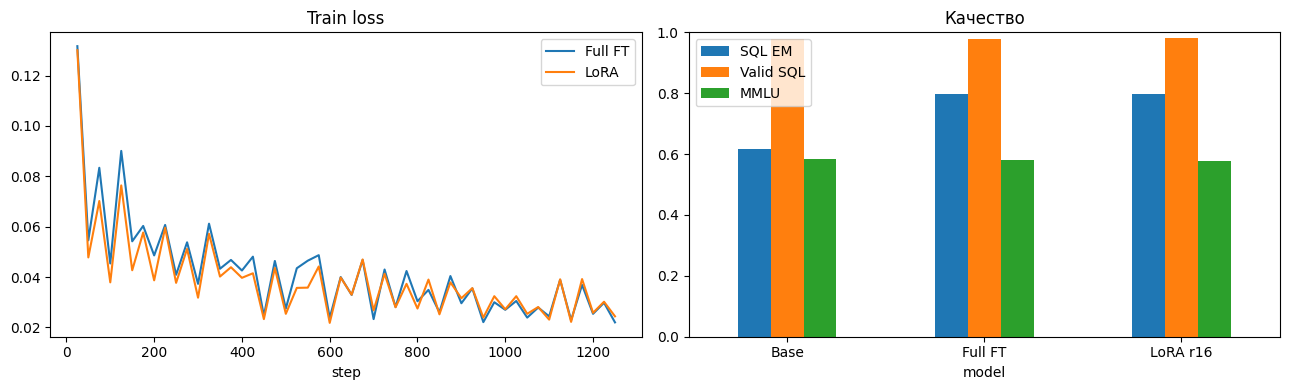

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, lbl in [("full_ft", "Full FT"), ("lora_main", "LoRA")]:
    s, l = zip(*RESULTS[name]["loss_curve"])
    ax[0].plot(s, l, label=lbl)
ax[0].set_title("Train loss"); ax[0].set_xlabel("step"); ax[0].legend()
m = main_table.set_index("model")[["SQL EM", "Valid SQL", "MMLU"]]
m.plot.bar(ax=ax[1], rot=0); ax[1].set_title("Качество"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/main_comparison.png", dpi=120); plt.show()

### Ручная оценка: 8 одинаковых тестовых примеров для трех моделей

In [18]:
MANUAL_IDX = list(np.random.RandomState(SEED).choice(len(eval_gen_df), size=8, replace=False))
P = {n: pd.read_csv(f"{OUT_DIR}/preds_{n}.csv") for n in ["base", "full_ft", "lora_main"]}
for k, i in enumerate(MANUAL_IDX):
    print(f"================ #{k} (test idx {i}) ================")
    print("SCHEMA  :", eval_gen_df.context[i])
    print("QUESTION:", eval_gen_df.question[i])
    print("GOLD    :", eval_gen_df.answer[i])
    for n, lbl in [("base", "BASE   "), ("full_ft", "FULL FT"), ("lora_main", "LORA   ")]:
        r = P[n].iloc[i]
        print(f"{lbl} : {str(r.raw_output).strip()[:400]!r}  | EM={r.em} valid={r.valid}")
    print()

================ #0 (test idx 361) ================
SCHEMA  : CREATE TABLE table_24850487_5 (field_goals VARCHAR, player VARCHAR)
QUESTION: How many field goals did Stacey Thomas have? 
GOLD    : SELECT field_goals FROM table_24850487_5 WHERE player = "Stacey Thomas"
BASE    : "SELECT COUNT(field_goals) FROM table_24850487_5 WHERE player = 'Stacey Thomas'"  | EM=False valid=True
FULL FT : 'SELECT COUNT(field_goals) FROM table_24850487_5 WHERE player = "Stacey Thomas"'  | EM=False valid=True
LORA    : 'SELECT COUNT(field_goals) FROM table_24850487_5 WHERE player = "Stacey Thomas"'  | EM=False valid=True

================ #1 (test idx 73) ================
SCHEMA  : CREATE TABLE table_16799784_9 (year_named VARCHAR, longitude VARCHAR)
QUESTION: How many years have a longitude measure of 20.0e?
GOLD    : SELECT COUNT(year_named) FROM table_16799784_9 WHERE longitude = "20.0E"
BASE    : "```sql\nSELECT COUNT(year_named) FROM table_16799784_9 WHERE longitude = '20.0e';\n```"  | EM=True valid

**Ручная оценка** на 8 одинаковых тестовых примерах (вывод ячейки выше). Шкала: 2 — запрос эквивалентен эталону, 1 — частично верно или спорно, 0 — неверно.

| # | Вопрос (кратко) | Base | Full FT | LoRA | Комментарий |
|---|---|---|---|---|---|
| 0 | How many field goals did … have? | 1 | 1 | 1 | Все три модели пишут `COUNT(field_goals)`, эталон выбирает значение колонки `field_goals`. Вопрос двусмысленный, разметка WikiSQL требует значение. |
| 1 | How many years have a longitude of 20.0e? | 1 | 2 | 2 | Base ответил в markdown-блоке и с литералом `'20.0e'`. EM засчитан, потому что нормализация приводит всё к нижнему регистру, но в SQLite сравнение строк регистрозависимо, и запрос вернёт другой результат. Дообученные модели написали `"20.0E"`, как в разметке. |
| 2 | power when city of license is belleville | 2 | 2 | 2 | |
| 3 | Date with outcome runner-up and surface carpet | 2 | 2 | 2 | Base в markdown-блоке с `;`, после извлечения совпадает с эталоном. |
| 4 | names of all the products | 2 | 2 | 2 | |
| 5 | position of the Saskatchewan player | 2 | 2 | 2 | |
| 6 | position for University of Akron Michigan Bucks | 2 | 2 | 2 | Base в markdown-блоке. |
| 7 | height in inches of contestants from La Rioja | 2 | 0 | 0 | Дообученные модели добавили лишний `COUNT`, Base ответил верно. |
| **Итого из 16** | | **14** | **13** | **13** | |


## 10. Эксперименты: влияние гиперпараметров LoRA

Базовая точка: `r=16, alpha=32, dropout=0.05, target=all-linear, lr=2e-4`. В каждой группе меняется **один** параметр, остальные зафиксированы. Данные, число шагов, lr и seed одинаковые во всех прогонах.

* **r**: 4, 8, 16, 32, 64 при фиксированном `alpha=32`. Обратите внимание: масштаб обновления равен `alpha/r`, поэтому с ростом r он падает. Для разделения эффектов есть доп. группа с `alpha=2r`.
* **alpha**: 8, 16, 32, 64, 128 при r=16 (масштаб 0.5…8).
* **dropout**: 0.0, 0.05, 0.1, 0.3.
* **target_modules**: q+v, attention (q,k,v,o), MLP (gate,up,down), all-linear.
* **комбинации**: `alpha=2r` для r ∈ {4, 64}, rsLoRA (`alpha/√r`) при r=64.

In [19]:
B = LORA_MAIN
EXPERIMENTS = [
    # --- r (alpha фиксирован = 32) ---
    ("lora_r4",   "r", dict(B, r=4)),
    ("lora_r8",   "r", dict(B, r=8)),
    ("lora_r32",  "r", dict(B, r=32)),
    ("lora_r64",  "r", dict(B, r=64)),
    # --- alpha (r = 16) ---
    ("lora_a8",   "alpha", dict(B, alpha=8)),
    ("lora_a16",  "alpha", dict(B, alpha=16)),
    ("lora_a64",  "alpha", dict(B, alpha=64)),
    ("lora_a128", "alpha", dict(B, alpha=128)),
    # --- dropout ---
    ("lora_d0",   "dropout", dict(B, dropout=0.0)),
    ("lora_d0.1", "dropout", dict(B, dropout=0.1)),
    ("lora_d0.3", "dropout", dict(B, dropout=0.3)),
    # --- target_modules ---
    ("lora_t_qv",   "target_modules", dict(B, target_modules=QV)),
    ("lora_t_attn", "target_modules", dict(B, target_modules=ATTN)),
    ("lora_t_mlp",  "target_modules", dict(B, target_modules=MLP)),
    # --- комбинации ---
    ("lora_r4_a8",     "combo", dict(B, r=4, alpha=8)),
    ("lora_r64_a128",  "combo", dict(B, r=64, alpha=128)),
    ("lora_r64_rslora","combo", dict(B, r=64, alpha=32, use_rslora=True)),
]
for name, group, cfg in EXPERIMENTS:
    print(f"\n######## {name}: {cfg}")
    run_lora(name, group=group, **cfg)


######## lora_r4: {'r': 4, 'alpha': 32, 'dropout': 0.05, 'target_modules': ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']}


Step,Training Loss
25,0.127100
50,0.047800
75,0.072900
100,0.037600
125,0.074900
150,0.043500
175,0.056600
200,0.040200
225,0.058800
250,0.035500


[lora_r4] EM=0.806 valid=0.980 test_loss=0.0297 MMLU=0.575

######## lora_r8: {'r': 8, 'alpha': 32, 'dropout': 0.05, 'target_modules': ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']}


Step,Training Loss
25,0.129200
50,0.047600
75,0.073000
100,0.039900
125,0.077600
150,0.042700
175,0.057500
200,0.039300
225,0.058900
250,0.036600


[lora_r8] EM=0.792 valid=0.980 test_loss=0.0301 MMLU=0.573

######## lora_r32: {'r': 32, 'alpha': 32, 'dropout': 0.05, 'target_modules': ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']}


Step,Training Loss
25,0.130500
50,0.048400
75,0.070300
100,0.040400
125,0.077600
150,0.043100
175,0.058200
200,0.038900
225,0.058600
250,0.037000


... (25 outputs left out)

Step,Training Loss
25,0.111900
50,0.052400
75,0.075800
100,0.045200
125,0.081600
150,0.052800
175,0.070000
200,0.046800
225,0.059600
250,0.041600


[lora_r64_a128] EM=0.800 valid=0.976 test_loss=0.0290 MMLU=0.544

######## lora_r64_rslora: {'r': 64, 'alpha': 32, 'dropout': 0.05, 'target_modules': ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj'], 'use_rslora': True}


Step,Training Loss
25,0.105900
50,0.054800
75,0.075700
100,0.059700
125,0.105600
150,0.064600
175,0.089800
200,0.059400
225,0.090100
250,0.050600


[lora_r64_rslora] EM=0.806 valid=0.970 test_loss=0.0302 MMLU=0.487


## 11. Итоговая таблица

In [20]:
rows = []
for name, r in RESULTS.items():
    rows.append({"run": name, "method": r["method"], "group": r.get("group", ""),
                 "r": r.get("r"), "alpha": r.get("alpha"), "dropout": r.get("dropout"),
                 "target_modules": r.get("target_modules"), "rslora": r.get("rslora"), "lr": r.get("lr"),
                 "trainable_params": r["trainable_params"],
                 "% trainable": round(100 * r["trainable_params"] / r["total_params"], 3),
                 "train_min": round(r.get("train_time_s", np.nan) / 60, 2),
                 "peak_mem_GB": round(r.get("peak_mem_alloc_gb", np.nan), 2),
                 "train_loss": round(r.get("train_loss", np.nan), 4),
                 "test_loss": round(r["test_loss"], 4),
                 "SQL_EM": round(r["sql_em"], 4), "Valid_SQL": round(r["sql_valid"], 4), "MMLU": round(r["mmlu"], 4)})
final = pd.DataFrame(rows)
final.to_csv(f"{OUT_DIR}/final_results.csv", index=False)
final.sort_values(["method", "group", "run"]).reset_index(drop=True)

,run,method,group,r,alpha,dropout,target_modules,rslora,lr,trainable_params,% trainable,train_min,peak_mem_GB,train_loss,test_loss,SQL_EM,Valid_SQL,MMLU
0,base,base,,NaN,NaN,NaN,None,None,NaN,0,0.000,NaN,NaN,NaN,0.2480,0.616,0.978,0.583
1,full_ft,full_ft,,NaN,NaN,NaN,None,None,0.00001,1543714304,100.000,4.25,41.42,0.0416,0.0297,0.798,0.978,0.581
2,lora_a128,lora,alpha,16.0,128.0,0.05,q+k+v+o+gate+up+down,False,0.00020,18464768,1.182,4.42,35.03,0.0416,0.0295,0.802,0.980,0.548
3,lora_a16,lora,alpha,16.0,16.0,0.05,q+k+v+o+gate+up+down,False,0.00020,18464768,1.182,4.38,35.03,0.0409,0.0318,0.800,0.980,0.581
4,lora_a64,lora,alpha,16.0,64.0,0.05,q+k+v+o+gate+up+down,False,0.00020,18464768,1.182,4.48,35.03,0.0391,0.0285,0.804,0.980,0.568
5,lora_a8,lora,alpha,16.0,8.0,0.05,q+k+v+o+gate+up+down,False,0.00020,18464768,1.182,4.49,35.03,0.0429,0.0338,0.788,0.978,0.584
6,lora_main,lora,baseline,16.0,32.0,0.05,q+k+v+o+gate+up+down,False,0.00020,18464768,1.182,4.42,35.02,0.0391,0.0299,0.798,0.980,0.577
7,lora_r4_a8,lora,combo,4.0,8.0,0.05,q+k+v+o+gate+up+down,False,0.00020,4616192,0.298,4.42,34.93,0.0423,0.0337,0.790,0.980,0.580
8,lora_r64_a128,lora,combo,64.0,128.0,0.05,q+k+v+o+gate+up+down,False,0.00020,73859072,4.566,4.49,35.44,0.0412,0.0290,0.800,0.976,0.544
9,lora_r64_rslora,lora,combo,64.0,32.0,0.05,q+k+v+o+gate+up+down,True,0.00020,73859072,4.566,4.39,35.44,0.0475,0.0302,0.806,0.970,0.487


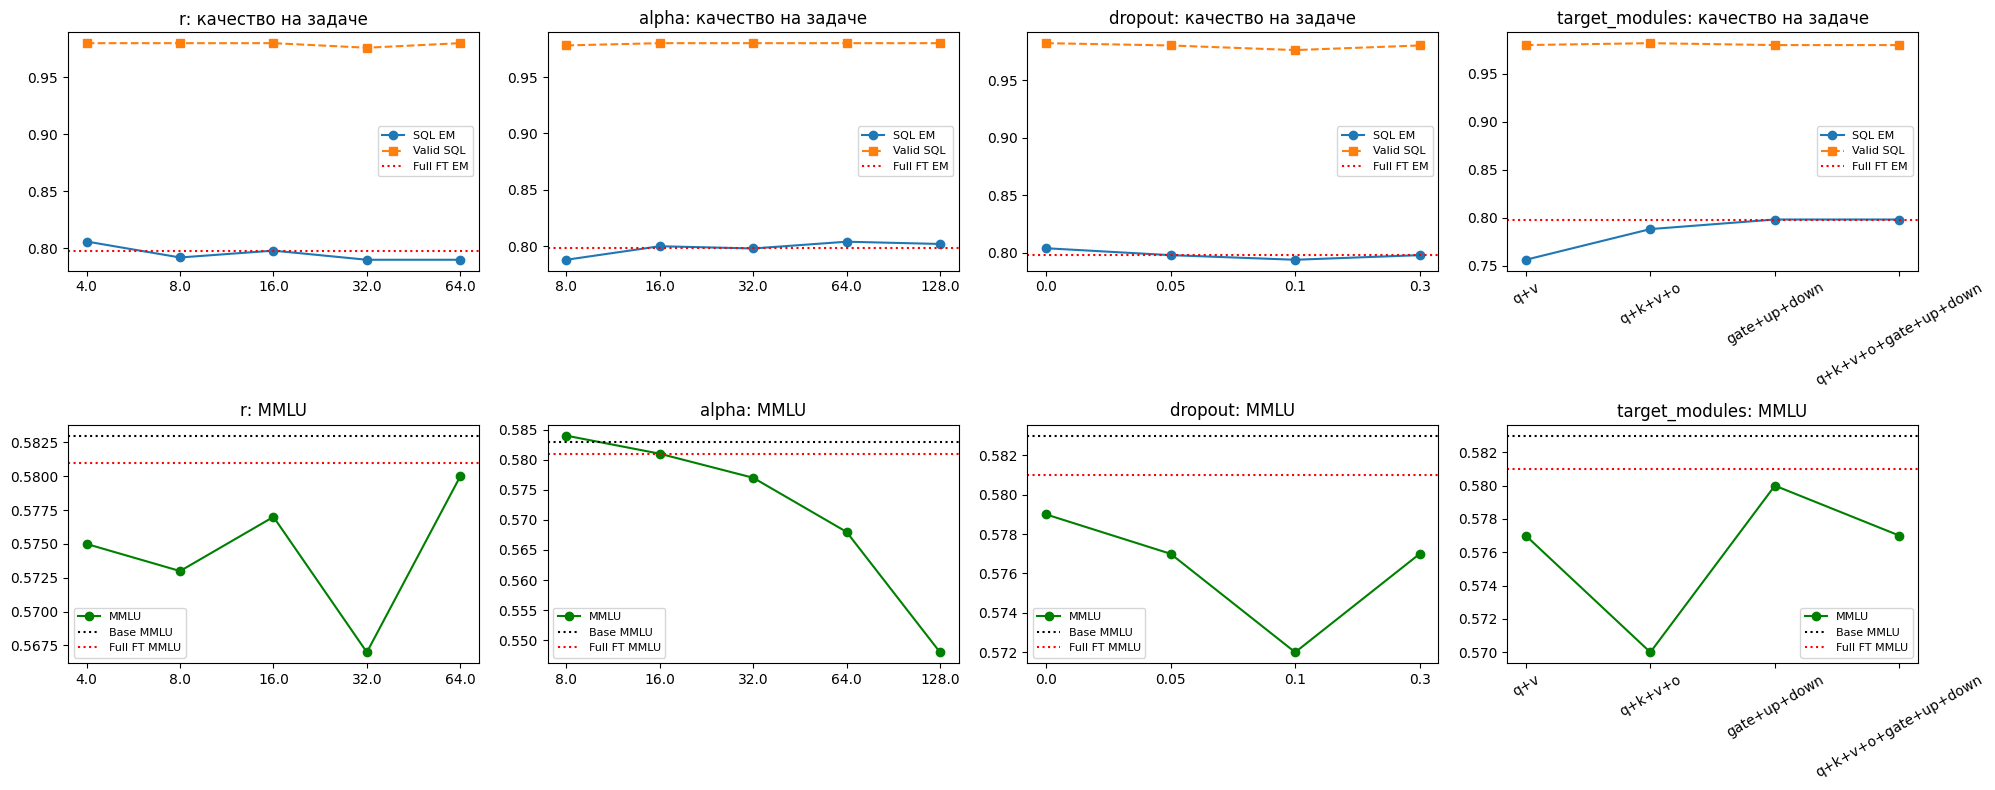

In [21]:
base_lora = final[final.run == "lora_main"]
def group_df(g, key):
    d = pd.concat([final[final.group == g], base_lora])
    return d.sort_values(key) if key != "target_modules" else d.sort_values("trainable_params")

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for j, (g, key) in enumerate([("r", "r"), ("alpha", "alpha"), ("dropout", "dropout"), ("target_modules", "target_modules")]):
    d = group_df(g, key)
    x = d[key].astype(str)
    axes[0, j].plot(x, d.SQL_EM, "o-", label="SQL EM"); axes[0, j].plot(x, d.Valid_SQL, "s--", label="Valid SQL")
    axes[0, j].axhline(RESULTS["full_ft"]["sql_em"], color="r", ls=":", label="Full FT EM")
    axes[0, j].set_title(f"{g}: качество на задаче"); axes[0, j].legend(fontsize=8)
    axes[1, j].plot(x, d.MMLU, "o-", color="g", label="MMLU")
    axes[1, j].axhline(RESULTS["base"]["mmlu"], color="k", ls=":", label="Base MMLU")
    axes[1, j].axhline(RESULTS["full_ft"]["mmlu"], color="r", ls=":", label="Full FT MMLU")
    axes[1, j].set_title(f"{g}: MMLU"); axes[1, j].legend(fontsize=8)
    if g == "target_modules":
        for ax in axes[:, j]: ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/lora_sweep.png", dpi=120); plt.show()

In [22]:
summ = []
for g in ["r", "alpha", "dropout", "target_modules", "combo"]:
    d = pd.concat([final[final.group == g], base_lora])
    best = d.loc[d.SQL_EM.idxmax()]
    summ.append({"параметр": g, "EM min": d.SQL_EM.min(), "EM max": d.SQL_EM.max(),
                 "Δ EM": round(d.SQL_EM.max() - d.SQL_EM.min(), 4),
                 "Δ MMLU": round(d.MMLU.max() - d.MMLU.min(), 4), "лучший прогон": best.run})
pd.DataFrame(summ)

,параметр,EM min,EM max,Δ EM,Δ MMLU,лучший прогон
0,r,0.790,0.806,0.016,0.013,lora_r4
1,alpha,0.788,0.804,0.016,0.036,lora_a64
2,dropout,0.794,0.804,0.010,0.007,lora_d0
3,target_modules,0.756,0.798,0.042,0.010,lora_t_mlp
4,combo,0.790,0.806,0.016,0.093,lora_r64_rslora


## 12. Анализ влияния параметров LoRA

Шум: стандартная ошибка EM на 500 примерах ≈ 1,8 п.п., MMLU на 1000 вопросах ≈ 1,6 п.п. Разницу меньше ~3,5 п.п. (2 SE) считаю незначимой. На каждый конфиг один seed.

Разброс метрик внутри группы (вместе с основным прогоном `lora_main`):

| Параметр | SQL EM, min–max | Δ EM | MMLU, min–max | Δ MMLU |
|---|---|---|---|---|
| r | 0.790–0.806 | 1,6 п.п. | 0.567–0.580 | 1,3 п.п. |
| alpha | 0.788–0.804 | 1,6 п.п. | 0.548–0.584 | 3,6 п.п. |
| dropout | 0.794–0.804 | 1,0 п.п. | 0.572–0.579 | 0,7 п.п. |
| target_modules | 0.756–0.798 | 4,2 п.п. | 0.570–0.580 | 1,0 п.п. |
| комбинации | 0.790–0.806 | 1,6 п.п. | 0.487–0.580 | 9,3 п.п. |



## 13. Финальный анализ: Full FT vs LoRA

| Критерий | Full FT | LoRA (r=16) |
|---|---|---|
| Обучаемые параметры | 1 543 714 304 (100%) | 18 464 768 (1,18%) |
| Время обучения | 4,25 мин | 4,42 мин |
| Пиковая GPU-память (allocated / reserved) | 41,42 / 65,49 ГБ | 35,02 / 38,00 ГБ |
| SQL EM / Valid SQL | 0.798 / 0.978 | 0.798 / 0.980 |
| Test loss | 0.0297 | 0.0299 |
| MMLU (Base: 0.583) | 0.581 | 0.577 |
| Размер артефакта | ~3,1 ГБ (bf16) | ~74 МБ (адаптер) |